# Hardcore Environment Code

## Setup

**Dependencies and imports**

This can take a minute...

In [2]:
%pip install swig
%pip install rldurham

  Obtaining dependency information for swig from https://files.pythonhosted.org/packages/a7/2f/7a6b14eea6d0247d3f803649f50df3cf3905714bd82f2c386fcfde9544f3/swig-4.4.1-py3-none-win_amd64.whl.metadata
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
    --------------------------------------- 0.1/2.5 MB 525.1 kB/s eta 0:00:05
    --------------------------------------- 0.1/2.5 MB 656.4 kB/s eta 0:00:04
   --- ------------------------------------ 0.2/2.5 MB 1.2 MB/s eta 0:00:03
   ---- ----------------------------------- 0.3/2.5 MB 1.5 MB/s eta 0:00:02
   ---- ----------------------------------- 0.3/2.5 MB 1.5 MB/s eta 0:00:02
   ------ --------------------------------- 0.4/2.5 MB 1.4 MB/s eta 0:00:02
   ------ --------------------------------- 0.4/2.5 MB 1.2 MB/s eta 0:00:02
   ---------- ----------------------------- 0.7/2.5 MB 1.8

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gensim 4.3.0 requires FuzzyTM>=0.4.0, which is not installed.
tables 3.8.0 requires blosc2~=2.0.0, which is not installed.
tables 3.8.0 requires cython>=0.29.21, which is not installed.
numba 0.57.1 requires numpy<1.25,>=1.21, but you have numpy 1.26.4 which is incompatible.


## TD3 (Twin Delayed Deep Deterministic Policy Gradient) for rldurham/Walker
Algorithm source:
  Fujimoto et al. (2018) "Addressing Function Approximation Error in Actor-Critic Methods"
  https://arxiv.org/abs/1802.09477

Official author implementation (reference for architecture & hyperparameters):
  https://github.com/sfujim/TD3

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""  # CPU only — Walker is I/O bound, not compute bound

import torch
import rldurham as rld
import gymnasium as gym
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
import collections, random

In [2]:
# Replay Buffer
# Source: standard experience replay (Mnih et al. 2015, https://arxiv.org/abs/1312.5602)

class ReplayBuffer:
    def __init__(self, buffer_limit):
        self.buffer = collections.deque(maxlen=buffer_limit)

    def put(self, transition):
        self.buffer.append(transition)

    def sample(self, n):
        mini_batch = random.sample(self.buffer, n)
        s, a, r, s_p, d = zip(*mini_batch)
        return (
            torch.tensor(np.array(s),   dtype=torch.float),
            torch.tensor(np.array(a),   dtype=torch.float),
            torch.tensor(np.array(r),   dtype=torch.float).unsqueeze(1),
            torch.tensor(np.array(s_p), dtype=torch.float),
            torch.tensor(np.array(d),   dtype=torch.float).unsqueeze(1),
        )

    def size(self):
        return len(self.buffer)

In [ ]:
# Actor Network  (deterministic policy)
# tanh output squashes actions to [-1, 1] to match Walker's action space bounds.

class Actor(nn.Module):
    def __init__(self, obs_dim, act_dim, lr=3e-4):
        super().__init__()
        # Add LayerNorm for better training stability (common in continuous control)
        self.net = nn.Sequential(
            nn.Linear(obs_dim, 256), nn.LayerNorm(256), nn.ReLU(),
            nn.Linear(256, 256),     nn.LayerNorm(256), nn.ReLU(),
            nn.Linear(256, 256),     nn.LayerNorm(256), nn.ReLU(),
            nn.Linear(256, act_dim), nn.Tanh(),
        )
        self.optimizer = optim.Adam(self.parameters(), lr=lr)

    def forward(self, s):
        return self.net(s)

In [ ]:
# Critic Network  (Q-function, scalar output)
# Source: Section 4 "Clipped Double Q-Learning" in Fujimoto et al. (2018).

class Critic(nn.Module):
    def __init__(self, obs_dim, act_dim, lr=3e-4):
        super().__init__()
        # Q1
        self.q1 = nn.Sequential(
            nn.Linear(obs_dim + act_dim, 256), nn.LayerNorm(256), nn.ReLU(),
            nn.Linear(256, 256),               nn.LayerNorm(256), nn.ReLU(),
            nn.Linear(256, 256),               nn.LayerNorm(256), nn.ReLU(),
            nn.Linear(256, 1),
        )
        # Q2: independent weights, same architecture
        self.q2 = nn.Sequential(
            nn.Linear(obs_dim + act_dim, 256), nn.LayerNorm(256), nn.ReLU(),
            nn.Linear(256, 256),               nn.LayerNorm(256), nn.ReLU(),
            nn.Linear(256, 256),               nn.LayerNorm(256), nn.ReLU(),
            nn.Linear(256, 1),
        )
        # Single optimiser over both critics
        self.optimizer = optim.Adam(self.parameters(), lr=lr)

    def forward(self, s, a):
        # Return both Q-values (used during critic training)
        x = torch.cat([s, a], dim=-1)
        return self.q1(x), self.q2(x)

    def q1_only(self, s, a):
        # Returns only Q1 (used during actor update, only need one critic)
        x = torch.cat([s, a], dim=-1)
        return self.q1(x)

    def soft_update(self, target, tau):
        # Polyak averaging
        # Source: Lillicrap et al. DDPG (2016) https://arxiv.org/abs/1509.02971
        for p_tgt, p in zip(target.parameters(), self.parameters()):
            p_tgt.data.copy_(p_tgt.data * (1.0 - tau) + p.data * tau)

In [ ]:
# TD3 Agent

class Agent(nn.Module):
    def __init__(
        self,
        env,
        lr_actor=3e-4,           # learning rate for actor; Fujimoto et al. Table 1
        lr_critic=3e-4,          # learning rate for critic; Fujimoto et al. Table 1
        gamma=0.99,              # discount factor; Fujimoto et al. Table 1
        tau=0.005,               # soft update rate; Fujimoto et al. Table 1
        buffer_limit=500_000,    # large buffer keeps diverse experiences; see SB3 defaults
        batch_size=256,          # Fujimoto et al. Table 1
        policy_noise=0.2,        # std of smoothing noise added to target actions
        noise_clip=0.5,          # clips smoothing noise to [-noise_clip, noise_clip]
        policy_delay=2,          # actor updated every d=2 critic steps
        expl_noise=0.2,          # Gaussian exploration noise std added to actions
        warmup_steps=15_000,     # random exploration before any training begins
        grad_steps_per_episode=200, # number of gradient updates to run after each episode 
    ):
        super().__init__()
        self.env = env
        self.gamma = gamma
        self.tau = tau
        self.batch_size = batch_size
        self.policy_noise = policy_noise
        self.noise_clip = noise_clip
        self.policy_delay = policy_delay
        self.initial_noise = expl_noise
        self.final_noise = 0.005  # minimum exploration noise for late training stages
        self.noise_decay_steps = 1_000_000
        self.warmup_steps = warmup_steps
        self.grad_steps_per_episode = grad_steps_per_episode

        self.total_steps = 0   # tracks environment interactions
        self.update_count = 0  # tracks gradient update steps (for delayed actor update)

        discrete_act, discrete_obs, self.act_dim, obs_dim = rld.env_info(env, print_out=True)

        self.memory = ReplayBuffer(buffer_limit)

        # Actor and its target (target used only for TD backup, not for action selection)
        self.actor        = Actor(obs_dim, self.act_dim, lr_actor)
        self.actor_target = Actor(obs_dim, self.act_dim, lr_actor)
        self.actor_target.load_state_dict(self.actor.state_dict())

        # Twin critic and its target
        self.critic        = Critic(obs_dim, self.act_dim, lr_critic)
        self.critic_target = Critic(obs_dim, self.act_dim, lr_critic)
        self.critic_target.load_state_dict(self.critic.state_dict())

    # Action selection 
    def action(self, s, add_noise=True):
        with torch.no_grad():
            s_t = torch.from_numpy(s).float().unsqueeze(0)
            a = self.actor(s_t).squeeze(0).numpy()

        if add_noise:
            # Add Gaussian exploration noise and clip to valid action range [-1, 1]
            # Implement linear decay of exploration noise over time (common practice)
            noise_scale = self.final_noise + (
                self.initial_noise - self.final_noise
            ) * max(0, (self.noise_decay_steps - self.total_steps)) / self.noise_decay_steps

            noise = np.random.normal(0, noise_scale, size=self.act_dim)
            a = np.clip(a + noise, -1.0, 1.0)

        return a

    def put(self, s, a, r, s_prime, done):
        self.memory.put((s, a, r, s_prime, done))

    # Gradient update step 
    def _update(self):
        mb = self.memory.sample(self.batch_size)
        s, a, r, s_prime, done_mask = mb

        # Critic update
        with torch.no_grad():
            # Target Policy Smoothing: add clipped noise to next action
            noise = torch.clamp(
                torch.randn_like(a) * self.policy_noise,
                -self.noise_clip,
                self.noise_clip
            )
            # Next action from target actor (smoothed)
            a_prime = torch.clamp(self.actor_target(s_prime) + noise, -1.0, 1.0)

            # Clipped Double Q: take min of both target critics to form TD target
            q1_next, q2_next = self.critic_target(s_prime, a_prime)
            q_next = torch.min(q1_next, q2_next)
            td_target = r + self.gamma * done_mask * q_next  # done_mask=0 at terminal

        # Compute loss for both critics simultaneously
        q1_val, q2_val = self.critic(s, a)
        # Use Huber loss (smooth L1) instead of MSE for better stability with outliers
        critic_loss = F.smooth_l1_loss(q1_val, td_target) + F.smooth_l1_loss(q2_val, td_target)

        self.critic.optimizer.zero_grad()
        critic_loss.backward()
        nn.utils.clip_grad_norm_(self.critic.parameters(), 1.0)  # prevents exploding gradients
        self.critic.optimizer.step()

        # Delayed Actor update 
        if self.update_count % self.policy_delay == 0:
            q_vals = self.critic.q1_only(s, self.actor(s))

            if self.total_steps > 500_000:
                # TD3+BC: normalised Q-maximisation + behavioural cloning
                # Source: Fujimoto & Gu (2021) https://arxiv.org/abs/2106.06860
                lam = 1.0 / (q_vals.abs().mean().detach() + 1e-8)
                actor_loss = -lam * q_vals.mean() + F.mse_loss(self.actor(s), a)
            else:
                actor_loss = -q_vals.mean()

            self.actor.optimizer.zero_grad()
            actor_loss.backward()
            nn.utils.clip_grad_norm_(self.actor.parameters(), 1.0)
            self.actor.optimizer.step()

            self.critic.soft_update(self.critic_target, self.tau)
            for p, p_tgt in zip(self.actor.parameters(), self.actor_target.parameters()):
                p_tgt.data.copy_(self.tau * p.data + (1 - self.tau) * p_tgt.data)

        self.update_count += 1

    def train(self):
        # Run gradient_steps_per_episode update steps after each episode
        if self.memory.size() < max(self.batch_size, self.warmup_steps):
            return
        for _ in range(self.grad_steps_per_episode):
            self._update()

    # Episode rollout 
    def episode(self):
        done = False
        s, _ = self.env.reset()
        info = {}
        while not done:
            # During warmup, take random actions to populate replay buffer with diverse experiences
            if self.total_steps < self.warmup_steps:
                a = self.env.action_space.sample()
            else:
                a = self.action(s, add_noise=True)

            s_prime, r, terminated, truncated, info = self.env.step(a)
            done = terminated or truncated
            not_done = 0.0 if terminated else 1.0

            # Assymmetric reward scaling
            scaled_r = r * 0.5 if r <= -10 else r * 3.0
            self.put(s, a, scaled_r, s_prime, not_done)
            s = s_prime
            self.total_steps += 1
        return info

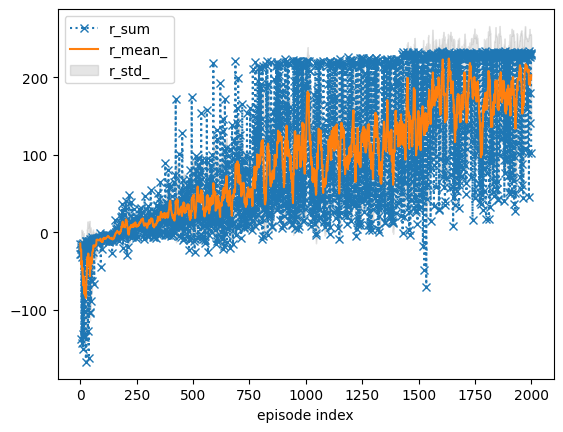

In [ ]:
env = rld.make("rldurham/Walker", render_mode="rgb_array", hardcore=True)
rld.seed_everything(42, env)

# reward clipping 
env = rld.transparent_wrapper(gym.wrappers.ClipReward)(env, min_reward=-10)

env = rld.Recorder(
    env,
    smoothing=10,
    video=True,
    video_folder="videos-hardcore",
    video_prefix="zzjw57-agent-video-hardcore",   
    logs=True,
)

recorder = env
recorder.video = False
tracker = rld.InfoTracker()

# Training loop 
agent = Agent(env)
max_episodes = 2000

for n_epi in range(max_episodes):
    recorder.video = (n_epi + 1) % 100 == 0  # record every 100 episodes

    info = agent.episode()
    env.add_stats(info, ignore_existing=True)
    tracker.track(info)
    agent.train()

    # First learning rate decay
    if n_epi == 1500:
        for param_group in agent.actor.optimizer.param_groups:
            param_group['lr'] = 1e-4
        for param_group in agent.critic.optimizer.param_groups:
            param_group['lr'] = 1e-4

    # Second learning rate decay
    if n_epi == 1800:
        for param_group in agent.actor.optimizer.param_groups:
            param_group['lr'] = 3e-5
        for param_group in agent.critic.optimizer.param_groups:
            param_group['lr'] = 3e-5

    # Final learning rate decay
    if n_epi == 1900:
        for param_group in agent.actor.optimizer.param_groups:
            param_group['lr'] = 1e-5
        for param_group in agent.critic.optimizer.param_groups:
            param_group['lr'] = 1e-5

    if (n_epi + 1) % 10 == 0:
        print(f"Episode {n_epi+1} | steps={agent.total_steps} | updates={agent.update_count}")
        tracker.plot(r_mean_=True, r_std_=True, r_sum=dict(linestyle=':', marker='x'))

env.close()
env.write_log(folder="logs-hardcore", file="zzjw57-agent-log-hardcore.txt") 